In [14]:
install.packages("dplyr")
install.packages("tidyr")
install.packages("ggplot2")
install.packages("knitr")
install.packages("broom")
library(dplyr)
library(tidyr)
library(ggplot2)
library(knitr)
library(broom)

cancer <- tibble::tribble(
  ~edad,      ~ciudad,      ~casos, ~poblacion,
  "40-54",   "Fredericia", 11,     3059,
  "55-59",   "Fredericia", 11,      800,
  "60-64",   "Fredericia", 11,      710,
  "65-69",   "Fredericia", 10,      581,
  "70-74",   "Fredericia", 11,      509,
  "Over 74", "Fredericia", 10,      605,

  "40-54",   "Horsens",    13,     2879,
  "55-59",   "Horsens",     6,     1083,
  "60-64",   "Horsens",    15,      923,
  "65-69",   "Horsens",    10,      834,
  "70-74",   "Horsens",    12,      634,
  "Over 74", "Horsens",     2,      782,

  "40-54",   "Kolding",     4,     3142,
  "55-59",   "Kolding",     8,     1050,
  "60-64",   "Kolding",     7,      895,
  "65-69",   "Kolding",    11,      702,
  "70-74",   "Kolding",     9,      535,
  "Over 74", "Kolding",    12,      659,

  "40-54",   "Vejle",       5,     2520,
  "55-59",   "Vejle",       7,      878,
  "60-64",   "Vejle",      10,      839,
  "65-69",   "Vejle",      14,      631,
  "70-74",   "Vejle",       8,      539,
  "Over 74", "Vejle",       7,      619
)

cancer <- cancer %>%
  mutate(
    edad = factor(edad, levels = c("40-54", "55-59", "60-64", "65-69", "70-74", "Over 74")),
    ciudad = factor(ciudad),
    tasa_1000 = 1000 * casos / poblacion
  )

kable(cancer, digits = 3, caption = "Datos de cáncer de pulmón: casos, población expuesta y tasa por 1000 habitantes.")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)





Table: Datos de cáncer de pulmón: casos, población expuesta y tasa por 1000 habitantes.

|edad    |ciudad     | casos| poblacion| tasa_1000|
|:-------|:----------|-----:|---------:|---------:|
|40-54   |Fredericia |    11|      3059|     3.596|
|55-59   |Fredericia |    11|       800|    13.750|
|60-64   |Fredericia |    11|       710|    15.493|
|65-69   |Fredericia |    10|       581|    17.212|
|70-74   |Fredericia |    11|       509|    21.611|
|Over 74 |Fredericia |    10|       605|    16.529|
|40-54   |Horsens    |    13|      2879|     4.515|
|55-59   |Horsens    |     6|      1083|     5.540|
|60-64   |Horsens    |    15|       923|    16.251|
|65-69   |Horsens    |    10|       834|    11.990|
|70-74   |Horsens    |    12|       634|    18.927|
|Over 74 |Horsens    |     2|       782|     2.558|
|40-54   |Kolding    |     4|      3142|     1.273|
|55-59   |Kolding    |     8|      1050|     7.619|
|60-64   |Kolding    |     7|       895|     7.821|
|65-69   |Kolding    |   

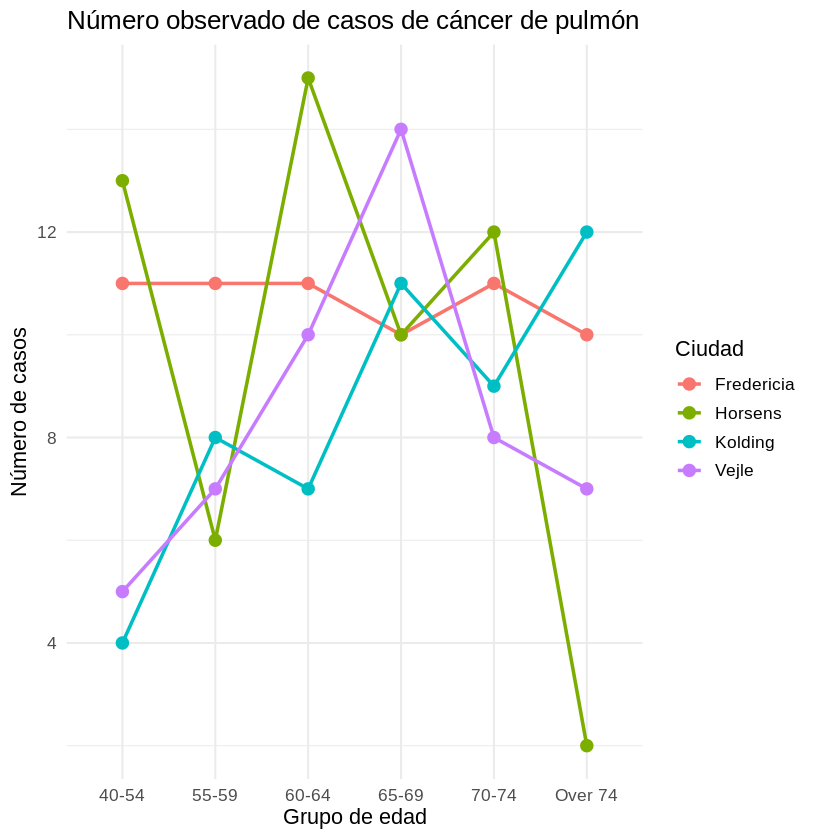

In [15]:
ggplot(cancer, aes(x = edad, y = casos, group = ciudad, color = ciudad)) +
  geom_line(linewidth = 1) +
  geom_point(size = 3) +
  labs(
    title = "Número observado de casos de cáncer de pulmón",
    x = "Grupo de edad",
    y = "Número de casos",
    color = "Ciudad"
  ) +
  theme_minimal(base_size = 13)

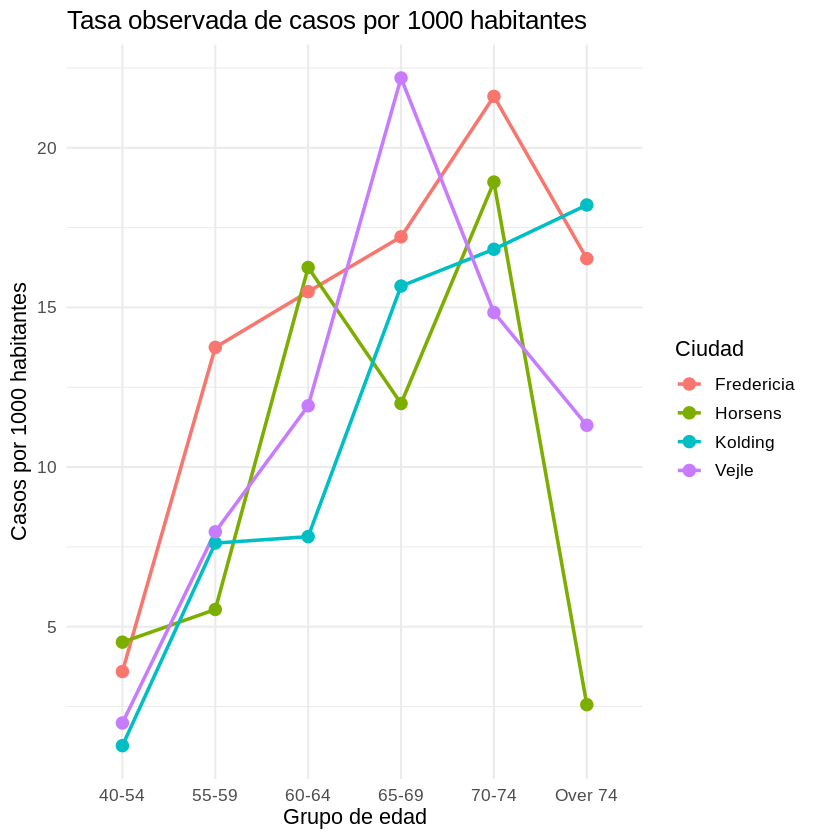

In [16]:
ggplot(cancer, aes(x = edad, y = tasa_1000, group = ciudad, color = ciudad)) +
  geom_line(linewidth = 1) +
  geom_point(size = 3) +
  labs(
    title = "Tasa observada de casos por 1000 habitantes",
    x = "Grupo de edad",
    y = "Casos por 1000 habitantes",
    color = "Ciudad"
  ) +
  theme_minimal(base_size = 13)

In [17]:
mod_pois <- glm(
  casos ~ ciudad + edad + offset(log(poblacion)),
  family = poisson(link = "log"),
  data = cancer
)

summary_mod <- summary(mod_pois)
summary_mod


Call:
glm(formula = casos ~ ciudad + edad + offset(log(poblacion)), 
    family = poisson(link = "log"), data = cancer)

Coefficients:
              Estimate Std. Error z value Pr(>|z|)    
(Intercept)    -5.6321     0.2003 -28.125  < 2e-16 ***
ciudadHorsens  -0.3301     0.1815  -1.818   0.0690 .  
ciudadKolding  -0.3715     0.1878  -1.978   0.0479 *  
ciudadVejle    -0.2723     0.1879  -1.450   0.1472    
edad55-59       1.1010     0.2483   4.434 9.23e-06 ***
edad60-64       1.5186     0.2316   6.556 5.53e-11 ***
edad65-69       1.7677     0.2294   7.704 1.31e-14 ***
edad70-74       1.8569     0.2353   7.891 3.00e-15 ***
edadOver 74     1.4197     0.2503   5.672 1.41e-08 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for poisson family taken to be 1)

    Null deviance: 129.908  on 23  degrees of freedom
Residual deviance:  23.447  on 15  degrees of freedom
AIC: 137.84

Number of Fisher Scoring iterations: 5


In [18]:
rr_tabla <- broom::tidy(mod_pois, conf.int = TRUE, exponentiate = TRUE) %>%
  mutate(
    interpretacion = case_when(
      estimate > 1 ~ "Mayor tasa que la referencia",
      estimate < 1 ~ "Menor tasa que la referencia",
      TRUE ~ "Sin cambio relativo"
    )
  ) %>%
  rename(
    termino = term,
    RR = estimate,
    IC_inf = conf.low,
    IC_sup = conf.high,
    valor_p = p.value
  )

kable(rr_tabla, digits = 3, caption = "Rate Ratios estimados para el modelo Poisson.")



Table: Rate Ratios estimados para el modelo Poisson.

|termino       |    RR| std.error| statistic| valor_p| IC_inf| IC_sup|interpretacion               |
|:-------------|-----:|---------:|---------:|-------:|------:|------:|:----------------------------|
|(Intercept)   | 0.004|     0.200|   -28.125|   0.000|  0.002|  0.005|Menor tasa que la referencia |
|ciudadHorsens | 0.719|     0.182|    -1.818|   0.069|  0.503|  1.026|Menor tasa que la referencia |
|ciudadKolding | 0.690|     0.188|    -1.978|   0.048|  0.476|  0.995|Menor tasa que la referencia |
|ciudadVejle   | 0.762|     0.188|    -1.450|   0.147|  0.525|  1.099|Menor tasa que la referencia |
|edad55-59     | 3.007|     0.248|     4.434|   0.000|  1.843|  4.901|Mayor tasa que la referencia |
|edad60-64     | 4.566|     0.232|     6.556|   0.000|  2.907|  7.236|Mayor tasa que la referencia |
|edad65-69     | 5.857|     0.229|     7.704|   0.000|  3.748|  9.249|Mayor tasa que la referencia |
|edad70-74     | 6.404|     0.235| 

In [19]:
cancer_aug <- cancer %>%
  mutate(
    mu_hat = fitted(mod_pois),
    tasa_hat_1000 = 1000 * mu_hat / poblacion,
    resid_pearson = residuals(mod_pois, type = "pearson"),
    resid_deviance = residuals(mod_pois, type = "deviance")
  )

kable(
  cancer_aug %>% select(edad, ciudad, casos, poblacion, tasa_1000, mu_hat, tasa_hat_1000),
  digits = 3,
  caption = "Casos observados, casos ajustados y tasas ajustadas por 1000 habitantes."
)



Table: Casos observados, casos ajustados y tasas ajustadas por 1000 habitantes.

|edad    |ciudad     | casos| poblacion| tasa_1000| mu_hat| tasa_hat_1000|
|:-------|:----------|-----:|---------:|---------:|------:|-------------:|
|40-54   |Fredericia |    11|      3059|     3.596| 10.955|         3.581|
|55-59   |Fredericia |    11|       800|    13.750|  8.615|        10.769|
|60-64   |Fredericia |    11|       710|    15.493| 11.609|        16.351|
|65-69   |Fredericia |    10|       581|    17.212| 12.187|        20.976|
|70-74   |Fredericia |    11|       509|    21.611| 11.673|        22.932|
|Over 74 |Fredericia |    10|       605|    16.529|  8.960|        14.811|
|40-54   |Horsens    |    13|      2879|     4.515|  7.412|         2.574|
|55-59   |Horsens    |     6|      1083|     5.540|  8.384|         7.742|
|60-64   |Horsens    |    15|       923|    16.251| 10.849|        11.755|
|65-69   |Horsens    |    10|       834|    11.990| 12.576|        15.080|
|70-74   |Horsens

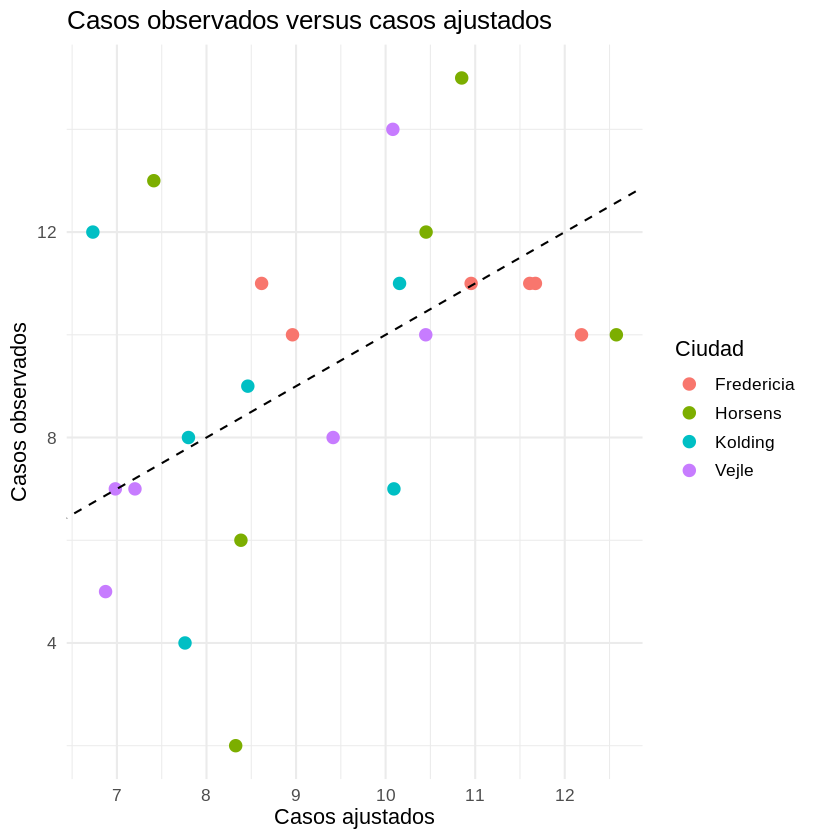

In [20]:
ggplot(cancer_aug, aes(x = mu_hat, y = casos, color = ciudad)) +
  geom_point(size = 3) +
  geom_abline(intercept = 0, slope = 1, linetype = "dashed") +
  labs(
    title = "Casos observados versus casos ajustados",
    x = "Casos ajustados",
    y = "Casos observados",
    color = "Ciudad"
  ) +
  theme_minimal(base_size = 13)

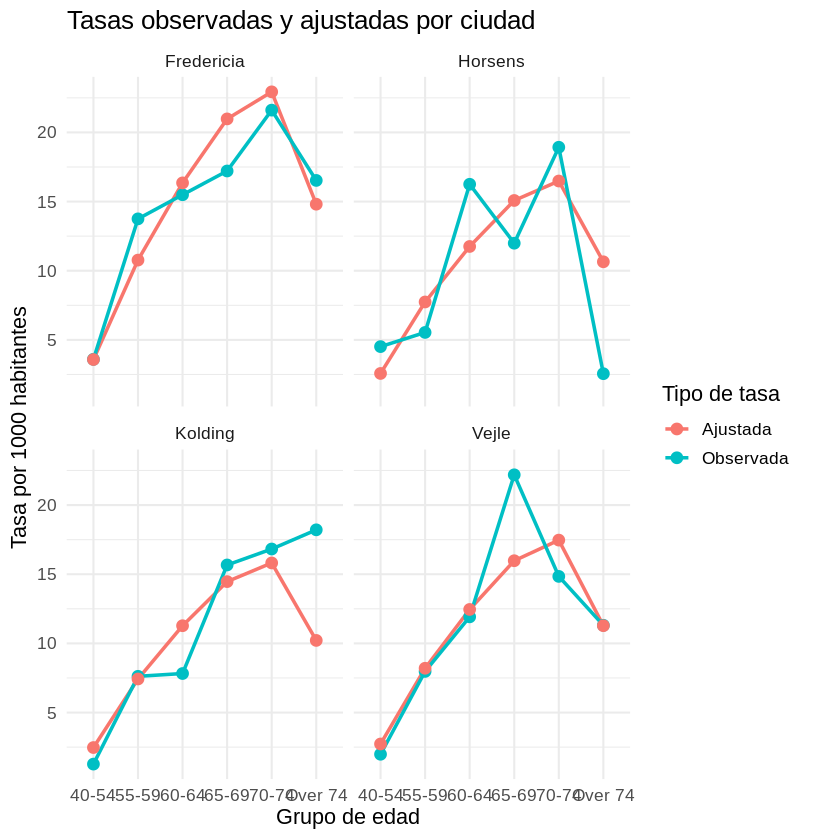

In [21]:
cancer_long <- cancer_aug %>%
  select(edad, ciudad, tasa_1000, tasa_hat_1000) %>%
  pivot_longer(
    cols = c(tasa_1000, tasa_hat_1000),
    names_to = "tipo",
    values_to = "tasa"
  ) %>%
  mutate(
    tipo = recode(tipo,
                  tasa_1000 = "Observada",
                  tasa_hat_1000 = "Ajustada")
  )

ggplot(cancer_long, aes(x = edad, y = tasa, group = tipo, color = tipo)) +
  geom_line(linewidth = 1) +
  geom_point(size = 2.8) +
  facet_wrap(~ ciudad) +
  labs(
    title = "Tasas observadas y ajustadas por ciudad",
    x = "Grupo de edad",
    y = "Tasa por 1000 habitantes",
    color = "Tipo de tasa"
  ) +
  theme_minimal(base_size = 13)

In [22]:
dev <- deviance(mod_pois)
df_res <- df.residual(mod_pois)
p_dev <- pchisq(dev, df = df_res, lower.tail = FALSE)

pearson_x2 <- sum(residuals(mod_pois, type = "pearson")^2)
p_pearson <- pchisq(pearson_x2, df = df_res, lower.tail = FALSE)
phi_hat <- pearson_x2 / df_res

bondad <- tibble::tibble(
  medida = c("Deviance", "Pearson X2", "Dispersión estimada phi = X2/(n-p)"),
  valor = c(dev, pearson_x2, phi_hat),
  grados_libertad = c(df_res, df_res, NA),
  valor_p = c(p_dev, p_pearson, NA)
)

kable(bondad, digits = 4, caption = "Medidas de bondad de ajuste del modelo Poisson.")



Table: Medidas de bondad de ajuste del modelo Poisson.

|medida                             |   valor| grados_libertad| valor_p|
|:----------------------------------|-------:|---------------:|-------:|
|Deviance                           | 23.4475|              15|  0.0751|
|Pearson X2                         | 22.5616|              15|  0.0939|
|Dispersión estimada phi = X2/(n-p) |  1.5041|              NA|      NA|

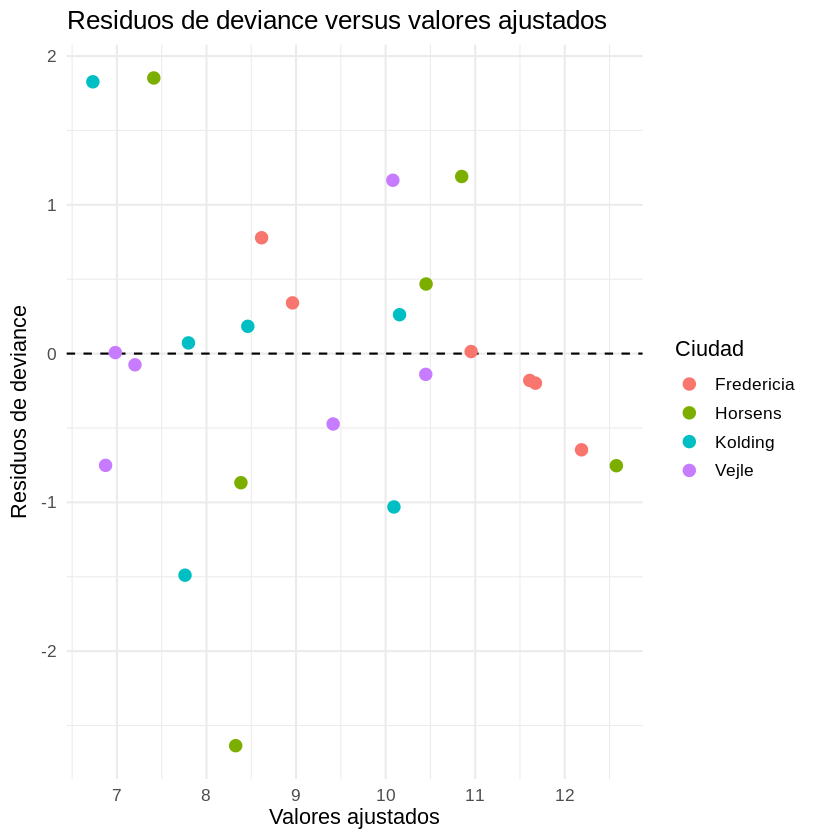

In [23]:
ggplot(cancer_aug, aes(x = mu_hat, y = resid_deviance, color = ciudad)) +
  geom_hline(yintercept = 0, linetype = "dashed") +
  geom_point(size = 3) +
  labs(
    title = "Residuos de deviance versus valores ajustados",
    x = "Valores ajustados",
    y = "Residuos de deviance",
    color = "Ciudad"
  ) +
  theme_minimal(base_size = 13)

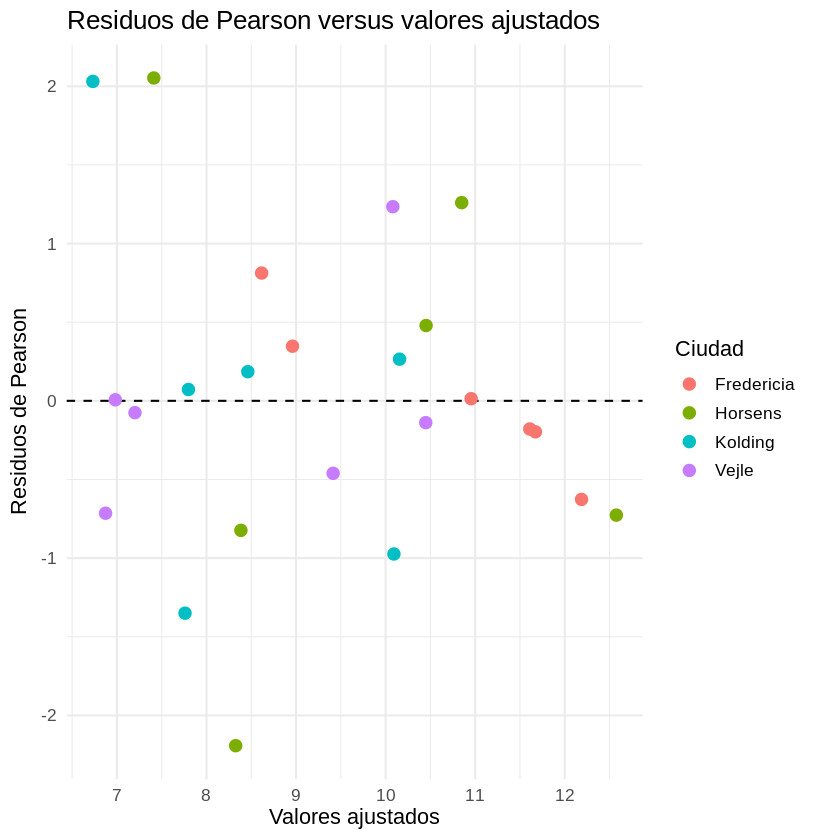

In [24]:
ggplot(cancer_aug, aes(x = mu_hat, y = resid_pearson, color = ciudad)) +
  geom_hline(yintercept = 0, linetype = "dashed") +
  geom_point(size = 3) +
  labs(
    title = "Residuos de Pearson versus valores ajustados",
    x = "Valores ajustados",
    y = "Residuos de Pearson",
    color = "Ciudad"
  ) +
  theme_minimal(base_size = 13)

In [25]:
mod_null <- glm(
  casos ~ 1 + offset(log(poblacion)),
  family = poisson(link = "log"),
  data = cancer
)

mod_edad <- glm(
  casos ~ edad + offset(log(poblacion)),
  family = poisson(link = "log"),
  data = cancer
)

mod_edad_ciudad <- glm(
  casos ~ edad + ciudad + offset(log(poblacion)),
  family = poisson(link = "log"),
  data = cancer
)

anova_tab <- anova(mod_null, mod_edad, mod_edad_ciudad, test = "Chisq")

kable(anova_tab, digits = 4, caption = "Comparación de modelos Poisson mediante diferencias de deviance.")



Table: Comparación de modelos Poisson mediante diferencias de deviance.

| Resid. Df| Resid. Dev| Df| Deviance| Pr(>Chi)|
|---------:|----------:|--:|--------:|--------:|
|        23|   129.9079| NA|       NA|       NA|
|        18|    28.3065|  5| 101.6014|   0.0000|
|        15|    23.4475|  3|   4.8590|   0.1824|

In [26]:
mod_quasi <- glm(
  casos ~ ciudad + edad + offset(log(poblacion)),
  family = quasipoisson(link = "log"),
  data = cancer
)

kable(
  broom::tidy(mod_quasi, conf.int = TRUE, exponentiate = TRUE) %>%
    rename(
      termino = term,
      RR = estimate,
      IC_inf = conf.low,
      IC_sup = conf.high,
      valor_p = p.value
    ),
  digits = 3,
  caption = "Rate Ratios estimados usando modelo Quasi-Poisson."
)



Table: Rate Ratios estimados usando modelo Quasi-Poisson.

|termino       |    RR| std.error| statistic| valor_p| IC_inf| IC_sup|
|:-------------|-----:|---------:|---------:|-------:|------:|------:|
|(Intercept)   | 0.004|     0.246|   -22.932|   0.000|  0.002|  0.006|
|ciudadHorsens | 0.719|     0.223|    -1.483|   0.159|  0.463|  1.112|
|ciudadKolding | 0.690|     0.230|    -1.613|   0.128|  0.437|  1.081|
|ciudadVejle   | 0.762|     0.230|    -1.182|   0.256|  0.482|  1.194|
|edad55-59     | 3.007|     0.305|     3.616|   0.003|  1.647|  5.481|
|edad60-64     | 4.566|     0.284|     5.346|   0.000|  2.625|  8.051|
|edad65-69     | 5.857|     0.281|     6.282|   0.000|  3.389| 10.284|
|edad70-74     | 6.404|     0.289|     6.434|   0.000|  3.642| 11.375|
|edadOver 74   | 4.136|     0.307|     4.625|   0.000|  2.252|  7.568|